<a href="https://colab.research.google.com/github/tanlen06-debug/Khai_Thac_Du_Lieu_Gr6/blob/bao-brand/notebooks/CLS_02_CLS_03_Dry_Bean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cài đặt thư viện
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from collections import Counter

print("Các thư viện đã được import thành công!")

Các thư viện đã được import thành công!


In [6]:
from google.colab import files

uploaded = files.upload()

Saving dry_bean.xlsx to dry_bean.xlsx


In [7]:
df = pd.read_excel("dry_bean.xlsx")

print("Kích thước dữ liệu:", df.shape)

display(df.head())

Kích thước dữ liệu: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [8]:
# Kiểm tra danh sách tên cột
print("Danh sách các cột:")
print(df.columns.tolist())

# Kiểm tra cột Class
print("\nCác loại hạt đậu:")
print(df["Class"].unique())

# Xác định dữ liệu đầu vào và đầu ra
X = df.drop(columns=["Class"])
y = df["Class"]

print("\nSố lượng thuộc tính X:", X.shape[1])
print("Số lượng nhãn y:", y.nunique())

print("\nKích thước X:", X.shape)
print("Kích thước y:", y.shape)

Danh sách các cột:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Các loại hạt đậu:
['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']

Số lượng thuộc tính X: 16
Số lượng nhãn y: 7

Kích thước X: (13611, 16)
Kích thước y: (13611,)


In [9]:
from sklearn.model_selection import train_test_split

# Chia dữ liệu thành tập Train và Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Kiểm tra kích thước dữ liệu
print("Kích thước tập Train:", X_train.shape)
print("Kích thước tập Test:", X_test.shape)

print("\nKích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

Kích thước tập Train: (10888, 16)
Kích thước tập Test: (2723, 16)

Kích thước y_train: (10888,)
Kích thước y_test: (2723,)


In [10]:
# Tính tỷ lệ phân bố các lớp
print("TỶ LỆ PHÂN BỐ DỮ LIỆU GỐC:")
print(y.value_counts(normalize=True).sort_index().round(4))

print("\nTỶ LỆ PHÂN BỐ TẬP TRAIN:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nTỶ LỆ PHÂN BỐ TẬP TEST:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

TỶ LỆ PHÂN BỐ DỮ LIỆU GỐC:
Class
BARBUNYA    0.0971
BOMBAY      0.0384
CALI        0.1198
DERMASON    0.2605
HOROZ       0.1417
SEKER       0.1489
SIRA        0.1937
Name: proportion, dtype: float64

TỶ LỆ PHÂN BỐ TẬP TRAIN:
Class
BARBUNYA    0.0971
BOMBAY      0.0384
CALI        0.1198
DERMASON    0.2606
HOROZ       0.1416
SEKER       0.1489
SIRA        0.1937
Name: proportion, dtype: float64

TỶ LỆ PHÂN BỐ TẬP TEST:
Class
BARBUNYA    0.0973
BOMBAY      0.0382
CALI        0.1197
DERMASON    0.2604
HOROZ       0.1418
SEKER       0.1491
SIRA        0.1935
Name: proportion, dtype: float64


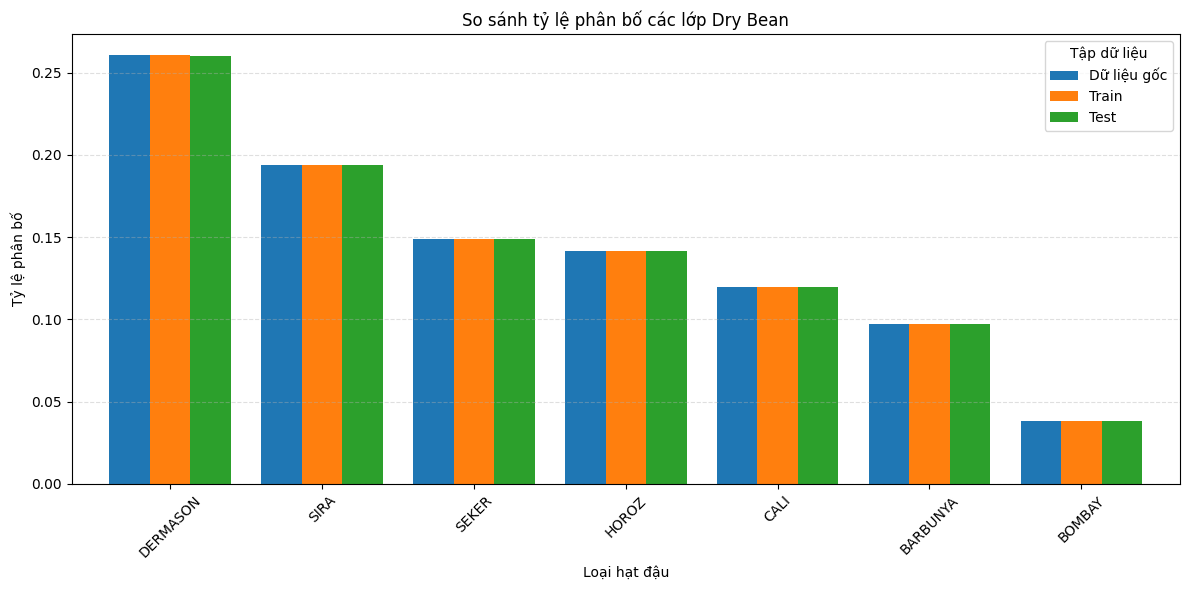

In [11]:
import matplotlib.pyplot as plt

# Tạo bảng tỷ lệ phân bố
distribution = pd.DataFrame({
    "Dữ liệu gốc": y.value_counts(normalize=True),
    "Train": y_train.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True)
})

# Vẽ biểu đồ
distribution.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("So sánh tỷ lệ phân bố các lớp Dry Bean")
plt.xlabel("Loại hạt đậu")
plt.ylabel("Tỷ lệ phân bố")
plt.xticks(rotation=45)
plt.legend(title="Tập dữ liệu")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [12]:
# Chia dữ liệu lần thứ hai với cùng random_state
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Kiểm tra kết quả
print("Train giống nhau:",
      X_train.equals(X_train_2))

print("Test giống nhau:",
      X_test.equals(X_test_2))

print("Nhãn Train giống nhau:",
      y_train.equals(y_train_2))

print("Nhãn Test giống nhau:",
      y_test.equals(y_test_2))

Train giống nhau: True
Test giống nhau: True
Nhãn Train giống nhau: True
Nhãn Test giống nhau: True


## Kết luận CLS-02: Chia tập dữ liệu Train/Test

Dữ liệu Dry Bean gồm 13.611 mẫu và 16 thuộc tính đầu vào. Nhóm đã sử dụng hàm train_test_split của thư viện Scikit-learn để chia dữ liệu thành hai tập:

- Tập Train: 10.888 mẫu (80%).
- Tập Test: 2.723 mẫu (20%).

Trong quá trình chia dữ liệu, nhóm sử dụng stratify=y để duy trì tỷ lệ phân bố của 7 lớp hạt đậu giữa tập Train và Test. Kết quả kiểm tra cho thấy tỷ lệ các lớp giữa dữ liệu gốc, Train và Test gần như tương đồng.

Ngoài ra, nhóm sử dụng random_state=42 để đảm bảo khả năng tái lập. Kết quả kiểm tra hai lần chia dữ liệu cho thấy cả X_train, X_test, y_train và y_test đều giống nhau.

**Kết luận:** Quá trình chia dữ liệu đã đáp ứng yêu cầu về phân tầng lớp và khả năng tái lập, tạo cơ sở cho các bước xây dựng và đánh giá mô hình Machine Learning tiếp theo.